In [1390]:
import torch
import numpy as np
from sklearn.datasets import load_wine, load_digits
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix
from sklearn.model_selection import StratifiedKFold
from torch import Tensor
from torch.nn import Sequential, Linear, ReLU, CrossEntropyLoss, Module
from torch.utils.data import DataLoader, Dataset
from torch.optim import Adam, SGD, AdamW, RMSprop
from sklearn.preprocessing import StandardScaler, MinMaxScaler, LabelEncoder
import matplotlib.pyplot as plt

In [1391]:
class MyDataset(Dataset):
    def __init__(self, datas: np.ndarray, labels: np.ndarray) -> None:
        self._x = torch.from_numpy(datas).float()
        self._y = torch.from_numpy(labels).long()

    def __len__(self) -> int:
        return len(self._x)

    def __getitem__(self, idx: int) -> tuple[Tensor, Tensor]:
        int(idx)
        return self._x[idx], self._y[idx]

In [1392]:
class CustomModel(Module):
    def __init__(self, input_size: int, output_size) -> None:
        super().__init__()
        self.net = Sequential(
            Linear(input_size, 32),
            ReLU(),
            Linear(32,16),
            ReLU(),
            Linear(16, output_size)
        )

    def forward(self, x: Tensor) -> Tensor:
        return self.net(x)

In [1393]:
def train_model_class(features, targets, kf, batch, epochs, criterion, exp=False ):
    encoder = LabelEncoder()
    targets = encoder.fit_transform(targets)
    num_classes = len(encoder.classes_)
    acc_scores = []
    f1_scores = []
    folds_loss = []
    folds_acc = []
    for i, (train_index, test_index) in enumerate(kf.split(features, targets)):
        print(f"Treinando modelo ----- Fold {i + 1}")
        scaler = StandardScaler()
        x_train_scaled = scaler.fit_transform(features[train_index])
        x_test_scaled = features[test_index]
        train_data = MyDataset(features[train_index], targets[train_index])
        train_loader = DataLoader(train_data, batch_size=batch)
    
        num_features = features.shape[1]

        #model = CustomModel(num_features, 5)
        #optmizer = Adam(model.parameters(), lr=0.001) #otimizador sdg nao ficou bom

        model = CustomModel(num_features, num_classes)
        optmizer = Adam(model.parameters(), lr=0.001) #momentum=0.9, weight_decay=1e-4

        epoch_loss = []
        epoch_acc = []
        for i_epochs in range(epochs):    
            model.train()
            batches_loss = []
            batches_acc = []
            for x, y in train_loader:
                optmizer.zero_grad()
                output = model(x)
                loss = criterion(output, y)
                loss.backward()
                optmizer.step()
                batches_loss.append(loss.item())
                batches_acc.append(accuracy_score(y, torch.argmax(output, dim=1).cpu().numpy()))

            epoch_loss.append(np.mean(batches_loss))
            epoch_acc.append(np.mean(batches_acc))

        folds_loss.append(epoch_loss)
        folds_acc.append(epoch_acc)
        model.eval()
        with torch.no_grad():
            x_test_tensor = Tensor(x_test_scaled).float() #features[test_index]
            y_true = targets[test_index]
            output = model(x_test_tensor)
            result = torch.argmax(output, dim=1).cpu().numpy()
            acc_s = accuracy_score(y_true, result)
            f1_s = f1_score(y_true, result, average="macro")
            cm = confusion_matrix(y_true, result)
            acc_scores.append(acc_s)
            f1_scores.append(f1_s)
            print(f"Acc: {acc_s}")
            print(f"F1-Score: {f1_s}")
            print(f"CM: {cm}")

        if exp:
           break

    print(f"\nResultado modelo ----- Acc: {np.mean(acc_scores)}, F1-Score: {np.mean(f1_scores)}")

    return folds_loss, folds_acc

In [1394]:
def plot_loss(folds_loss, folds_acc):
    # Converte para array numpy para conseguir multiplicar todos os valores por 100
    folds_acc = np.array(folds_acc, dtype=object) * 100
    
    for idx, fold_l in enumerate(folds_loss):
        fig, ax1 = plt.subplots(figsize=(7, 3))
        
        x = np.arange(len(fold_l)) # Usar np.arange é mais direto para épocas
        
        # Eixo esquerdo (Erro / Loss)
        ax1.plot(x, fold_l, color="red", label="Erro (Loss)")
        ax1.set_xlabel("Épocas")
        ax1.set_ylabel("Erro", color="red")
        
        # Eixo direito (Acurácia)
        ax2 = ax1.twinx()
        ax2.plot(x, folds_acc[idx], color="blue", label="Acurácia (%)")
        ax2.set_ylabel("Acurácia (%)", color="blue")
        
        # Ajuste correto do limite para porcentagem (0 a 100%)
        # Se sua acurácia nunca cai abaixo de 50%, você pode usar (50, 100) para dar zoom
        ax2.set_ylim(0, 110) 
        
        ax2.grid(True, linestyle="--", alpha=0.6)
        
        # Junta as legendas dos dois eixos em uma só
        lines_1, labels_1 = ax1.get_legend_handles_labels()
        lines_2, labels_2 = ax2.get_legend_handles_labels()
        ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc="center right")
        
        plt.title(f"Desempenho - Fold {idx + 1}")
        plt.tight_layout()
        plt.show() # plt.show() exibe o gráfico corretamente

In [1395]:
dataset = load_wine()
features = dataset.data
targets = dataset.target

In [1396]:
criterion = CrossEntropyLoss()
max_epochs = 200
batch = 8
kf = StratifiedKFold(n_splits=5, shuffle=True)

In [1397]:
folds_loss, folds_acc = train_model_class(features, targets, kf, batch, max_epochs, criterion, True)

Treinando modelo ----- Fold 1
Acc: 0.9722222222222222
F1-Score: 0.9740129935032483
CM: [[11  1  0]
 [ 0 14  0]
 [ 0  0 10]]

Resultado modelo ----- Acc: 0.9722222222222222, F1-Score: 0.9740129935032483


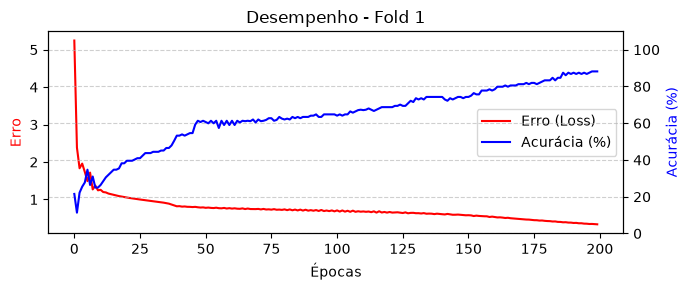

In [1398]:
plot_loss(folds_loss, folds_acc)